# Tutorial for Lab 10: Attention, Multi-Head Attention, Transformers & BERT

This tutorial **teaches the ideas** you need for Lab 10. It does *not* contain the lab answers — you will write those yourself. Each section has:
* 💡 **Intuition** — the idea in plain words
* 🔬 **Mini demo** — a tiny runnable example (run it, change numbers, break it!)
* ✅ **Lab checklist** — what you must be able to do before moving on
* ⚠️ **Common mistakes**

**How to use it:** open in Colab, run cells top to bottom *while* working through the lab. Estimated time: 45–60 min.

## 0. Where Lab 10 fits

| Lab | What you did | Key idea |
|---|---|---|
| 8 | LSTM encoder-decoder + **attention** | Decoder can "look back" at all encoder states |
| 9 | Fine-tuned a pre-trained **Transformer** (Marian) | Attention *replaces* recurrence; pre-training helps |
| **10** | Build attention **from scratch**, then fine-tune **BERT** | Open the black box, then see why pre-training wins |

**Lab 10 roadmap**
```
tokens -> embeddings (+ position) -> [ multi-head self-attention -> add&norm -> feed-forward -> add&norm ] x N -> [CLS] / pooled vector -> classifier
```
In the lab you build this by hand (small), then use the huge pre-trained version (BERT) and compare.

## 1. Tokenization — how text becomes numbers

💡 **Intuition:** neural networks need integers. BERT uses **WordPiece**: common words stay whole, rare words are split into pieces so there are never "unknown" words.

* `[CLS]` — added first. Its final vector is used as the **sentence summary** for classification.
* `[SEP]` — marks the end of a sentence.
* `##piece` — a continuation of the previous piece.
* `attention_mask` — 1 = real token, 0 = padding (so attention can ignore padding).

In [ ]:
!pip install -q transformers datasets evaluate accelerate bertviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 2.0 MB/s eta 0:00:00


In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")

for s in ["I love this movie!", "Unbelievably transformative cinematography"]:
    enc = tok(s)
    print(s)
    print("  tokens:", tok.convert_ids_to_tokens(enc["input_ids"]))
    print("  ids   :", enc["input_ids"])

# padding in a batch -> look at the attention_mask
batch = tok(["short one", "a noticeably longer sentence here"], padding=True)
print(batch["attention_mask"])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

I love this movie!
  tokens: ['[CLS]', 'i', 'love', 'this', 'movie', '!', '[SEP]']
  ids   : [101, 1045, 2293, 2023, 3185, 999, 102]
Unbelievably transformative cinematography
  tokens: ['[CLS]', 'un', '##bel', '##ie', '##va', '##bly', 'transform', '##ative', 'cinematography', '[SEP]']
  ids   : [101, 4895, 8671, 2666, 3567, 6321, 10938, 8082, 16434, 102]
[[1, 1, 1, 1, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1]]


🔬 **Try it:** tokenize a word with a typo, an emoji, and a word from another language. What happens?

✅ **Lab checklist:** you can explain `[CLS]`, `[SEP]`, `##`, and why we need an attention mask.

⚠️ **Common mistake:** padding *every* sentence to a fixed huge length wastes time. Lab uses *dynamic padding* (pad per batch).

## 2. Attention — the core idea

💡 **Intuition (library analogy)**
* Every token creates a **Query** ("what am I looking for?"), a **Key** ("what do I contain?") and a **Value** ("what information do I give?").
* A token compares its Query with *every* Key → similarity scores.
* Softmax turns scores into weights that sum to 1.
* The output is a **weighted average of Values**.

$$\text{Attention}(Q,K,V)=\text{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

**Compared to Lab 8:** there the *decoder state* was the query and the *encoder states* were keys/values (cross-attention). In **self-attention** all three come from the *same* sentence, so each word looks at all the other words in its own sentence.

### 2.1 Do it by hand (3 tokens, 2 dimensions)
We use NumPy so you can see every number. *(In the lab you'll write the general, batched PyTorch version.)*

In [ ]:
import numpy as np
np.set_printoptions(precision=2, suppress=True)

# 3 tokens, each represented by a 2-d vector (pretend these are Q, K, V already)
Q = np.array([[1., 0.], [0., 1.], [1., 1.]])
K = np.array([[1., 0.], [0., 1.], [1., 1.]])
V = np.array([[10., 0.], [0., 10.], [5., 5.]])

scores = Q @ K.T                      # (3,3): how much token i matches token j
print("scores:\n", scores)

def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))   # subtract max for numerical stability
    return e / e.sum(axis=-1, keepdims=True)

weights = softmax(scores / np.sqrt(2))              # sqrt(d_k) with d_k = 2
print("\nweights (rows sum to 1):\n", weights, "\nrow sums:", weights.sum(1))

output = weights @ V
print("\noutput:\n", output)

scores:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]

weights (rows sum to 1):
 [[0.4  0.2  0.4 ]
 [0.2  0.4  0.4 ]
 [0.25 0.25 0.5 ]] 
row sums: [1. 1. 1.]

output:
 [[6.02 3.98]
 [3.98 6.02]
 [5.   5.  ]]


🔬 **Try it:** change `K` so token 0 and token 2 are identical. Which weights change? Why?

### 2.2 Why divide by √d_k?
For large `d_k`, dot products get large → softmax becomes almost one-hot → tiny gradients. Dividing keeps scores at a sane size.

In [ ]:
rng = np.random.default_rng(0)
for dk in [4, 64, 512]:
    q, k = rng.standard_normal((10, dk)), rng.standard_normal((10, dk))
    raw = q @ k.T
    print(f"d_k={dk:4d} | std raw={raw.std():6.2f} | std scaled={ (raw/np.sqrt(dk)).std():5.2f} "
          f"| avg max-weight raw={softmax(raw).max(1).mean():.2f} scaled={softmax(raw/np.sqrt(dk)).max(1).mean():.2f}")

d_k=   4 | std raw=  1.84 | std scaled= 0.92 | avg max-weight raw=0.37 scaled=0.24
d_k=  64 | std raw=  6.64 | std scaled= 0.83 | avg max-weight raw=0.87 scaled=0.29
d_k= 512 | std raw= 25.50 | std scaled= 1.13 | avg max-weight raw=1.00 scaled=0.39


### 2.3 Masking — ignoring padding
Padding tokens are fake. We must stop real tokens from attending to them. Trick: **before softmax**, add a huge negative number (e.g. −1e9) to scores of padded positions → `exp(−1e9) ≈ 0` → weight ≈ 0.

In [ ]:
scores = np.array([[2.0, 1.0, 3.0, 0.5]])           # 4 keys; the last two are padding
mask   = np.array([[1,   1,   0,   0  ]])           # 1=keep, 0=ignore

print("without mask:", softmax(scores))
print("with mask   :", softmax(np.where(mask == 1, scores, -1e9)))

without mask: [[0.23 0.09 0.63 0.05]]
with mask   : [[0.73 0.27 0.   0.  ]]


✅ **Lab checklist (Part 2):**
* [ ] I can state the shapes: `Q,K,V = (batch, heads, T, d_k)`, `scores = (batch, heads, T, T)`
* [ ] I know *where* the mask is applied (before softmax) and why
* [ ] I know every row of the weight matrix sums to 1

⚠️ **Common mistakes**
* Transposing the wrong dimensions: you need `K.transpose(-2, -1)` (swap the last two), not the whole tensor.
* Applying softmax over the wrong axis — it must be over the **keys** (last axis).
* Mask with 0 instead of −1e9: `exp(0)=1`, which does *not* remove the token.

## 3. Multi-Head Attention — many views in parallel

💡 **Intuition:** one head gives one weighted average per word, which forces it to mix all kinds of relationships. With `h` heads, each head works in its own smaller subspace (`d_k = d_model / h`) and can specialise — e.g. one tracks the previous word, another links verbs to subjects, another looks at punctuation. Their outputs are concatenated and mixed by a final linear layer `W_o`.

```
x (B,T,d_model) --W_q--> (B,T,d_model) --split--> (B,h,T,d_k) --attention--> (B,h,T,d_k) --merge--> (B,T,d_model) --W_o--> (B,T,d_model)
```

### 3.1 The hardest part is the tensor reshaping — practise it
Each head sees a *slice* of the feature dimension. Run this to see how shapes change (no learning happens here).

In [ ]:
import torch
B, T, d_model, h = 2, 5, 8, 4
d_k = d_model // h

x = torch.arange(B * T * d_model).float().view(B, T, d_model)
print("start           :", tuple(x.shape))

heads = x.view(B, T, h, d_k)            # cut the feature axis into h chunks of d_k
print("after view      :", tuple(heads.shape))

heads = heads.transpose(1, 2)           # bring 'heads' before 'time' so attention runs per head
print("after transpose :", tuple(heads.shape), "= (B, h, T, d_k)")

# merging back is the reverse. Note: after transpose the tensor is not contiguous in memory,
# so .view() would fail here; .reshape() (or .contiguous().view()) works.
merged = heads.transpose(1, 2).reshape(B, T, h * d_k)
print("merged back     :", tuple(merged.shape), "| identical to start:", torch.equal(merged, x))

start           : (2, 5, 8)
after view      : (2, 5, 4, 2)
after transpose : (2, 4, 5, 2) = (B, h, T, d_k)
merged back     : (2, 5, 8) | identical to start: True


🔬 **Try it:** replace `.reshape` with `.view` in the merge step and read the error message. This is the #1 bug in the lab.

### 3.2 Parameter bookkeeping
Multi-head attention with `d_model=128` has **4 linear layers** of size 128×128 (+bias): `W_q, W_k, W_v, W_o`. The number of heads does **not** change the parameter count — it only changes how the same features are split.

In [ ]:
import torch.nn as nn
for heads in [1, 4, 8]:
    mha = nn.MultiheadAttention(128, heads)          # PyTorch's built-in layer, just for counting
    n = sum(p.numel() for p in mha.parameters())
    print(f"heads={heads}: total parameters = {n:,}  (same for every head count)")

heads=1: total parameters = 66,048  (same for every head count)
heads=4: total parameters = 66,048  (same for every head count)
heads=8: total parameters = 66,048  (same for every head count)


✅ **Lab checklist (Part 3.1–3.2):**
* [ ] I can explain why `d_model` must be divisible by `num_heads`
* [ ] I can write the shape after each step (project → split → attend → merge → `W_o`)
* [ ] I know how to verify my layer: copy its weights into `nn.MultiheadAttention` and compare outputs (**hint:** PyTorch stores Q,K,V stacked in `in_proj_weight`, shape `(3·d, d)`)

⚠️ **Common mistakes**
* Using `.view` after `.transpose` (error: *"view size is not compatible…"*) → use `.reshape`.
* Forgetting `batch_first=True` when creating `nn.MultiheadAttention` for the comparison.
* Putting the model in train mode when comparing outputs — dropout makes results differ; use `.eval()` and `torch.no_grad()`.

## 4. Positional Encoding — giving the model a sense of order

💡 **Intuition:** attention compares *all pairs of tokens at once*. "dog bites man" and "man bites dog" would look identical (just reordered). So we **add** a position-dependent vector to each embedding.

Sinusoidal idea: every dimension is a sine or cosine wave; low dimensions oscillate fast, high dimensions slowly — like the digits of a clock (seconds, minutes, hours), giving each position a unique "fingerprint".

$$PE_{(pos,2i)}=\sin\!\Big(\tfrac{pos}{10000^{2i/d}}\Big),\quad PE_{(pos,2i+1)}=\cos\!\Big(\tfrac{pos}{10000^{2i/d}}\Big)$$

🔬 **Demo:** just the *idea* — a few dimensions of the encoding plotted over positions. (Building the full matrix is your lab task.)

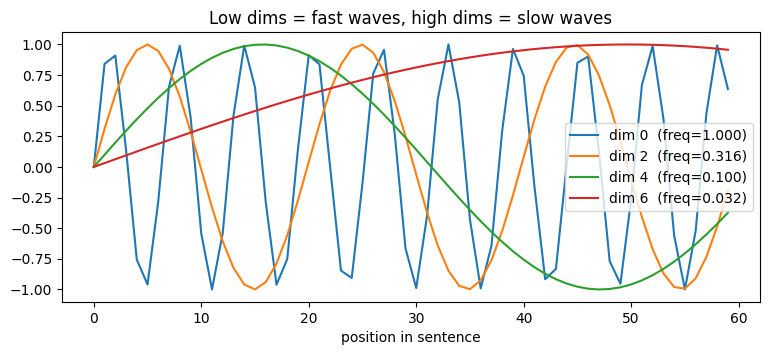

In [ ]:
import matplotlib.pyplot as plt
pos = np.arange(0, 60)
d = 16
plt.figure(figsize=(9, 3.5))
for i in [0, 2, 4, 6]:                           # pick a few "even" dimensions
    freq = 1 / (10000 ** (i / d))
    plt.plot(pos, np.sin(pos * freq), label=f"dim {i}  (freq={freq:.3f})")
plt.xlabel("position in sentence"); plt.legend(); plt.title("Low dims = fast waves, high dims = slow waves")
plt.show()

✅ **Lab checklist:** I know it is **added** (not concatenated) to embeddings, it is **not trained**, and I can use `register_buffer` for fixed tensors inside an `nn.Module`.

💬 **Think:** BERT actually uses *learned* position embeddings instead of sinusoids. What are the pros/cons? (Hint: what happens for sentences longer than the maximum length seen in training?)

## 5. The Transformer Encoder Block

```
        x ─────────────┐
        │              │ (residual / skip)
   Multi-Head Attn     │
        │              │
     Dropout           │
        └──── + ◄──────┘
          LayerNorm
        x' ────────────┐
        │              │ (residual)
  Linear → GELU → Linear   (feed-forward: d_model → d_ff → d_model)
        │              │
     Dropout           │
        └──── + ◄──────┘
          LayerNorm
```

| Piece | Why it is there |
|---|---|
| Self-attention | lets every token gather information from every other token |
| Feed-forward network | processes each token independently — adds non-linearity and capacity |
| **Residual connection** | gives gradients a shortcut through deep stacks; each layer only learns a *refinement* |
| **LayerNorm** | keeps activations on a stable scale → faster, steadier training |
| Dropout | regularisation |

🔬 **Mini demo — why residuals matter:** pass a signal through many random layers with and without a skip connection.

In [ ]:
torch.manual_seed(0)
layers = [nn.Linear(64, 64) for _ in range(30)]
x0 = torch.randn(1, 64)

plain, resid = x0.clone(), x0.clone()
for L in layers:
    plain = torch.tanh(L(plain))             # no skip: signal shrinks/distorts
    resid = resid + 0.1 * torch.tanh(L(resid))   # skip: original signal is preserved
print("norm after 30 layers  | plain:", plain.norm().item(), "| with residual:", resid.norm().item())
print("cosine similarity to input | plain:", torch.cosine_similarity(plain, x0).item(),
      "| residual:", torch.cosine_similarity(resid, x0).item())

norm after 30 layers  | plain: 0.7100329399108887 | with residual: 8.387237548828125
cosine similarity to input | plain: -0.10023577511310577 | residual: 0.9734663963317871


✅ **Lab checklist:** my block's output shape equals its input shape `(B, T, d_model)` (otherwise blocks can't be stacked!). Test with a random tensor before using it.

## 6. Training a model from scratch — the 5-line loop

Every PyTorch training step does the same five things:

```
optimizer.zero_grad()      # 1. clear old gradients
logits = model(inputs)     # 2. forward pass
loss = loss_fn(logits, y)  # 3. measure error
loss.backward()            # 4. compute gradients
optimizer.step()           # 5. update weights
```
Other things to remember:
* `model.train()` before training, `model.eval()` + `torch.no_grad()` for evaluation.
* Move **both** model and data to the same device (`.to(device)`).
* **Pooling:** the encoder outputs one vector per token; to classify a *sentence* we need one vector. Simplest: average the token vectors **ignoring padding** (multiply by the mask, divide by the number of real tokens).

🔬 **Demo — why masked pooling:** padding must not dilute the average.

In [ ]:
x = torch.tensor([[[1., 1.], [3., 3.], [0., 0.], [0., 0.]]])      # 2 real tokens + 2 padding vectors
m = torch.tensor([[1, 1, 0, 0]]).unsqueeze(-1).float()
print("naive mean :", x.mean(1))
print("masked mean:", (x * m).sum(1) / m.sum(1))

naive mean : tensor([[1., 1.]])
masked mean: tensor([[2., 2.]])


⚠️ **Common mistakes**
* Loss not decreasing → learning rate too high/low, or labels not aligned with inputs.
* `RuntimeError: Expected all tensors to be on the same device` → forgot `.to(device)` on a batch.
* Accuracy stuck near 50% on SST-2 → the model is guessing; check mask shape `(B,1,1,T)` and that you pool correctly.
* Remember: a small model trained on 5,000 sentences **will not** be great — that's the point of the comparison later.

## 7. BERT and Fine-Tuning

💡 **Intuition:** **Pre-training** = BERT reads billions of words and learns to *fill in masked words* ("The cat sat on the [MASK]"). It learns grammar and meaning. **Fine-tuning** = we then train it a little on our small labelled task (SST-2) so it learns "sentiment".

| | Our mini-Transformer | BERT-base |
|---|---|---|
| Layers / heads / hidden | 2 / 4 / 128 | 12 / 12 / 768 |
| Parameters | ~4M | ~110M |
| Pre-trained | ❌ | ✅ (3.3 B words) |
| Direction | bidirectional encoder | bidirectional encoder |

### 7.1 See what BERT predicts for a masked word (that's its pre-training task)

In [ ]:
from transformers import pipeline
fill = pipeline("fill-mask", model="bert-base-uncased")
for r in fill("The movie was absolutely [MASK], I loved every minute.")[:4]:
    print(f"{r['token_str']:12s} {r['score']:.3f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


amazing      0.134
perfect      0.119
fantastic    0.105
wonderful    0.096


### 7.2 Inspect the model you'll fine-tune
`AutoModelForSequenceClassification` = BERT body + a **new, randomly-initialised linear layer** on top of `[CLS]`. (The warning "some weights are newly initialized" is *expected*.)

In [ ]:
from transformers import AutoModelForSequenceClassification
bert = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)

total = sum(p.numel() for p in bert.parameters())
head  = sum(p.numel() for p in bert.classifier.parameters())
print(f"total params: {total:,} | classifier head only: {head:,}")
print(bert.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


total params: 109,483,778 | classifier head only: 1,538
Linear(in_features=768, out_features=2, bias=True)


### 7.3 Freezing = training only the head
Setting `p.requires_grad = False` stops a parameter from being updated. If you freeze all of BERT's body, only the tiny head learns, so BERT acts as a *fixed feature extractor*.

**Think before the lab:** which will be better — full fine-tuning or frozen? Which will be faster? Why? Write your prediction down, then compare with your results.

### 7.4 The Hugging Face `Trainer` — the pieces you need to configure
You do **not** write the loop; `Trainer` does. You configure it:

| `TrainingArguments` option | Meaning | Lab value |
|---|---|---|
| `learning_rate` | step size. **Small** (2e-5) when fine-tuning so we don't destroy pre-trained knowledge; larger if only the head trains | 2e-5 |
| `num_train_epochs` | passes over the data | 3 |
| `per_device_train_batch_size` | sentences per step | 32 |
| `weight_decay` | regularisation | 0.01 |
| `eval_strategy` | when to evaluate | `"epoch"` |
| `fp16` | mixed precision, faster on GPU | `True` on GPU |
| `report_to` | logging service | `"none"` |

You also pass: the `model`, `train_dataset`, `eval_dataset`, a `data_collator` (does dynamic padding) and `compute_metrics`.

`compute_metrics` receives `(logits, labels)`. Convert logits to predictions with `argmax` and return a dict like `{"accuracy": ..., "f1": ...}`.

📖 *Why F1 as well as accuracy?* Accuracy = fraction correct. **F1** = harmonic mean of precision (when I say "positive", am I right?) and recall (did I find all positives?). F1 matters when classes are imbalanced.

### 7.5 Pipelines
A `pipeline` bundles tokenizer + model + post-processing. Quick way to try any model on raw text:

In [ ]:
clf = pipeline("sentiment-analysis")          # downloads a ready-made English sentiment model
print(clf(["I loved it!", "Not good at all."]))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9998817443847656}, {'label': 'NEGATIVE', 'score': 0.9997897744178772}]


✅ **Lab checklist (Part 5):**
* [ ] I can explain pre-training vs fine-tuning
* [ ] I know why the learning rate is small
* [ ] I can count trainable parameters: `sum(p.numel() for p in model.parameters() if p.requires_grad)`
* [ ] I record **training time** for every model (needed for the table)

⚠️ **Common mistakes**
* Forgetting `num_labels=2`.
* Using `evaluation_strategy` on new library versions — the argument is now `eval_strategy`.
* Dataset still contains the raw `sentence` column → remove text columns after tokenizing.
* Running out of GPU memory → lower the batch size or `max_length`.

## 8. Reading attention heatmaps

When you ask BERT for attentions (`output_attentions=True`) you get a **tuple with one tensor per layer**, each shaped `(batch, heads, T, T)`.

* **Row** = the token that is *looking* (query). **Column** = the token being *looked at* (key). Each row sums to 1.
* To plot one head: `attentions[layer][0, head]` → a `(T, T)` matrix → `sns.heatmap(..., xticklabels=tokens, yticklabels=tokens)`.

**Patterns to look for**

| Pattern | What the picture looks like | Meaning |
|---|---|---|
| Diagonal stripe | tokens attend to themselves/neighbours | local context head |
| Bright column at `[SEP]`/`[CLS]` | everyone attends to one special token | a "resting" / no-op pattern |
| Scattered off-diagonal spots | links between related words | syntactic or semantic relation |
| Uniform blur | no clear structure | common in an untrained or small model |

🔬 **Demo — drawing a heatmap from a made-up attention matrix:**

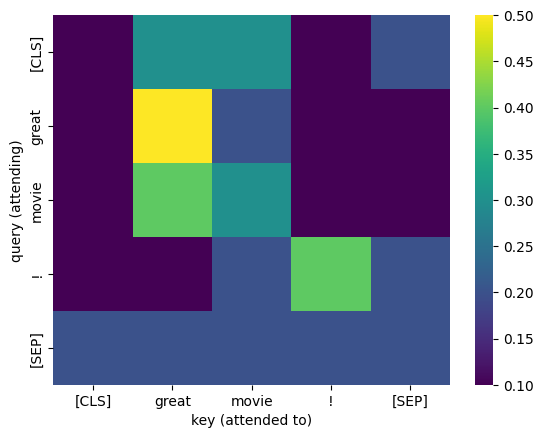

In [ ]:
import seaborn as sns
toks = ["[CLS]", "great", "movie", "!", "[SEP]"]
fake = np.array([[.1,.3,.3,.1,.2],
                 [.1,.5,.2,.1,.1],
                 [.1,.4,.3,.1,.1],
                 [.1,.1,.2,.4,.2],
                 [.2,.2,.2,.2,.2]])
sns.heatmap(fake, xticklabels=toks, yticklabels=toks, cmap="viridis")
plt.xlabel("key (attended to)"); plt.ylabel("query (attending)"); plt.show()

⚠️ **Common mistakes**
* `output_attentions=True` returns `None` → load the model with `attn_implementation="eager"`.
* Forgetting `torch.no_grad()` and `.cpu()` before converting to NumPy.
* `bertviz`'s `head_view(...)` must be the **last line** of the Colab cell.
* Don't over-interpret a single head — look at several layers and describe tendencies.

## 9. Debugging cheat-sheet

| Error / symptom | Likely cause | Fix |
|---|---|---|
| `view size is not compatible with input tensor's size and stride` | `.view` after `.transpose` | use `.reshape` |
| `mat1 and mat2 shapes cannot be multiplied` | wrong dim order in a matmul / transposed wrong axes | print `.shape` at each step |
| `Expected all tensors to be on the same device` | model on GPU, batch on CPU | `.to(device)` for both |
| Attention weights don't sum to 1 | softmax on wrong axis | `dim=-1` |
| Padded tokens get weight | mask missing/wrong shape | mask must broadcast to `(B,h,T,T)` → shape `(B,1,1,T)` |
| Loss is `nan` | learning rate too high / `-inf` in softmax of fully masked row | lower LR; use −1e9 not `-inf` |
| `CUDA out of memory` | batch/sequence too large | smaller batch, `max_length=64` |
| Same output after training | forgot `optimizer.zero_grad()/step()` or all params frozen | check `requires_grad` counts |

**Golden rule:** *print the shape of everything.* Most bugs in this lab are shape bugs.

## 10. Self-check quiz (try before looking at the answers!)

1. What are Q, K and V, and what does the softmax output represent?
2. Why do we divide by √d_k?
3. Why must `d_model` be divisible by the number of heads?
4. How does multi-head attention differ from single-head in *parameter count*?
5. Why does a Transformer need positional encoding but an LSTM does not?
6. What does the residual connection do in an encoder block?
7. Why is the learning rate for fine-tuning BERT much smaller than for training from scratch?
8. What is the difference between freezing BERT and fully fine-tuning it? Which has more trainable parameters?
9. Why can't BERT translate English to German on its own?
10. In `attentions[5][0, 3]`, what do the indices mean?

<details><summary><b>Click for answers</b></summary>

1. Q = what a token is looking for, K = what each token offers for matching, V = the information that gets passed on. The softmax output is a probability distribution over tokens: how much each token contributes to the current token's new representation.
2. Dot products grow with `d_k`; unscaled they push softmax into saturation (near one-hot) with tiny gradients. Dividing keeps scores at a stable scale.
3. Features are split evenly across heads, each head gets `d_k = d_model/h` dimensions.
4. There is no difference in the projection matrices: `W_q, W_k, W_v, W_o` are each `d_model × d_model` regardless of `h`.
5. Self-attention processes all tokens in parallel and ignores order; an LSTM reads tokens sequentially so order is built in.
6. It provides a shortcut for gradients and lets the block learn a *refinement* of its input, making deep stacks trainable.
7. The weights are already good; large updates would destroy that pre-trained knowledge ("catastrophic forgetting").
8. Frozen: only the classification head trains (~1.5k parameters) — fast but less accurate. Full fine-tuning updates all ~110M parameters — more accurate but slower. Full fine-tuning has more trainable parameters.
9. It is an encoder-only, bidirectional model trained for masked-word prediction; it has no decoder and cannot generate text token by token.
10. Layer 6 (index 5), first sentence in the batch, head 4 (index 3) → a `(T, T)` attention matrix.
</details>

## 11. Glossary

| Term | Meaning |
|---|---|
| Token | a unit of text (word or word-piece) |
| Embedding | a learned vector for each token |
| Self-attention | tokens attend to other tokens in the same sequence |
| Cross-attention | tokens in one sequence attend to another sequence (Lab 8 decoder→encoder) |
| Head | one parallel attention operation |
| `[CLS]` | special token whose output represents the whole sentence |
| Pre-training | learning general language knowledge from unlabeled text |
| Fine-tuning | adapting a pre-trained model to a specific labelled task |
| Frozen layer | a layer whose weights are not updated |
| F1 score | harmonic mean of precision and recall |

## 12. Further reading
* *The Illustrated Transformer* — Jay Alammar: https://jalammar.github.io/illustrated-transformer/
* *Attention Is All You Need* (Vaswani et al., 2017): https://arxiv.org/abs/1706.03762
* *BERT* (Devlin et al., 2018): https://arxiv.org/abs/1810.04805
* Hugging Face NLP Course: https://huggingface.co/learn/nlp-course

---
**Final tip:** build in small steps and test each piece on tiny random tensors *before* plugging it into the next one — attention → multi-head → encoder block → full model → training. Good luck! 🚀